# Week 7 group project: Landmark Detection
AI for Good - Minor ADSAI

[Open this notebook in Google Colab](https://colab.research.google.com/github/BTuyn/AI4G/blob/main/Week%207/Week7_Starter_Landmark_Detection.ipynb)

**Your group's mission:** build a very simple app (an MVP) that does
**landmark detection: finding points with a meaning, like a wrist, a knee or a nose** on photos you take yourselves, in or outside the school, find out how
good it is, and teach the rest of the class about it.

*Question for your group: where exactly are the important points - and what can you conclude from them?*

**Timeline**

| Time | What |
|------|------|
| 10:45-11:30 | **Phase 1 (45 min):** take photos and come up with your MVP - no laptops needed (read sections 1 and 3 for ideas) |
| 11:30 | **Stand-up:** 3 minutes per group - your MVP idea, your photos, who does what |
| 12:00-14:30 | **Phase 2:** photos into Colab, build the MVP and make it work, ground truth, evaluation, presentation (sections 0-8) |
| 14:45-15:30 | **Presentations:** your MVP, 10 minutes per group + 3 minutes questions |

**Your presentation must explain**

1. **What the technique is** - what goes in, what comes out, what it is used for (section 1)
2. **What data processing is needed** - from a phone photo to something the model can use, and the ground truth (sections 4 and 6)
3. **What you did** - your idea, your photos, how you built your MVP (sections 3 and 5)
4. **How you evaluate it** - which metric, why, and your result (section 7)
5. **The end result: your MVP** - show it working, and where it fails (section 8)

**Organise your group.** You are a big group, so split the work. A split
that works: a **photo team** (collects photos, makes the ground truth), a
**build team** (runs this notebook, builds the MVP), an **evaluation team**
(chooses and calculates the metric), and a **presentation team** (slides,
demo, timing). Pick one person who keeps an eye on the clock. Share this
notebook through Google Drive so everybody can see it.

## 0. Setup - run these cells once

The first cell is only needed for iPhone photos in HEIC format (or set the
iPhone camera to *Settings -> Camera -> Formats -> Most Compatible*). The
second cell loads the tools and some helpers:

- `upload_to("photos")` - choose photos on your laptop; they land in the folder `photos`
- `take_photo("photos", "name.jpg")` - take a photo with the laptop camera
- `load_folder("photos")` - load all photos of a folder: turned the right way up and made smaller
- `show([...])` - show pictures next to each other
- `save_result(name)` - save the picture you just made in the folder `results`, for your slides
- `download_results()` - download the folder `results` as a zip

In [4]:
%pip install torchvision

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 11.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# Only needed for iPhone HEIC photos
!pip install -q pillow-heif


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\milou\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [5]:
# Run, do not read
import warnings
warnings.filterwarnings("ignore")
import os, glob, base64, shutil, urllib.request, zipfile
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageOps
import torch
import torchvision.transforms.functional as TF
torch.set_grad_enabled(False)
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except ImportError:
    pass
os.makedirs("results", exist_ok=True)

def show(images, titles=None, size=3.5):
    if not isinstance(images, list):
        images = [images]
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    if len(images) == 1:
        axes = [axes]
    for k in range(len(images)):
        axes[k].imshow(images[k], cmap="gray" if images[k].ndim == 2 else None)
        axes[k].axis("off")
        if titles:
            axes[k].set_title(titles[k], fontsize=9)
    plt.show()

def save_result(name):
    # call this INSIDE the same cell, right after a picture is drawn
    plt.savefig(os.path.join("results", name), dpi=120, bbox_inches="tight")
    print("saved results/" + name)

def download_results():
    from google.colab import files
    shutil.make_archive("results", "zip", "results")
    files.download("results.zip")

def upload_to(folder):
    from google.colab import files
    os.makedirs(folder, exist_ok=True)
    for name, content in files.upload().items():
        with open(os.path.join(folder, name), "wb") as f:
            f.write(content)

def take_photo(folder, name):
    from IPython.display import display, Javascript
    from google.colab.output import eval_js
    os.makedirs(folder, exist_ok=True)
    display(Javascript('''
    async function takePhoto() {
      const div = document.createElement('div');
      const button = document.createElement('button');
      button.textContent = 'Capture';
      div.appendChild(button);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => button.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', 0.9);
    }'''))
    data_url = eval_js("takePhoto()")
    with open(os.path.join(folder, name), "wb") as f:
        f.write(base64.b64decode(data_url.split(",")[1]))
    print("saved", os.path.join(folder, name))

def load_folder(folder, max_size=1024):
    photos = {}
    for f in sorted(glob.glob(os.path.join(folder, "*"))):
        if "_mask" in os.path.basename(f):
            continue
        try:
            im = ImageOps.exif_transpose(Image.open(f)).convert("RGB")
        except Exception:
            print("skipped (not a photo):", f)
            continue
        im.thumbnail((max_size, max_size))
        photos[os.path.basename(f)] = np.array(im)
    print(folder, ":", len(photos), "photos")
    return photos

def download_examples(folder, urls):
    os.makedirs(folder, exist_ok=True)
    for url in urls:
        target = os.path.join(folder, url.split("/")[-1])
        if not os.path.exists(target):
            urllib.request.urlretrieve(url, target)

print("Ready")

Ready


## 1. What is landmark detection?

A **landmark** (or keypoint) is a point with a fixed meaning: the left wrist,
the right knee, the tip of the nose. A landmark detector finds those points
and gives each one an **x and y in pixels** (x from the left, **y from the
top**). Lines between them make a skeleton.

Our model, **Keypoint R-CNN** (trained on COCO), finds every person and **17
body landmarks** per person: nose, eyes, ears, shoulders, elbows, wrists, hips,
knees and ankles. The same idea exists for faces (68 points), hands (21),
animals and X-rays.

Because landmarks are numbers, you can calculate with them: is a wrist above
the shoulder? what is the angle of the knee? is the back straight?

In [6]:
# Run, do not read: a pre-trained landmark detector + helpers
from torchvision.models.detection import keypointrcnn_resnet50_fpn, KeypointRCNN_ResNet50_FPN_Weights
kp_weights = KeypointRCNN_ResNet50_FPN_Weights.DEFAULT
kp_model = keypointrcnn_resnet50_fpn(weights=kp_weights).eval()
POINTS = kp_weights.meta["keypoint_names"]
SKELETON = [(0, 1), (0, 2), (1, 3), (2, 4), (5, 6), (5, 7), (7, 9), (6, 8), (8, 10), (5, 11), (6, 12),
            (11, 12), (11, 13), (13, 15), (12, 14), (14, 16)]

def people(picture, threshold=0.8):
    out = kp_model([TF.to_tensor(picture)])[0]
    return [p.numpy()[:, :2] for p, s in zip(out["keypoints"], out["scores"]) if s >= threshold]

def body(picture):
    # the most confident person in the photo, or None
    found = people(picture, 0.5)
    return found[0] if found else None

def point(person, name):
    return person[POINTS.index(name)]           # [x, y]

def angle(person, a, b, c):
    # the angle at point b, in degrees, for example angle(person, "left_hip", "left_knee", "left_ankle")
    v1 = point(person, a) - point(person, b)
    v2 = point(person, c) - point(person, b)
    cos = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))
    return float(np.degrees(np.arccos(np.clip(cos, -1, 1))))

def draw(picture, persons, title="", grid=False):
    plt.figure(figsize=(6, 5))
    plt.imshow(picture)
    for p in persons:
        for a, b in SKELETON:
            plt.plot([p[a, 0], p[b, 0]], [p[a, 1], p[b, 1]], color="lime", linewidth=2)
        plt.scatter(p[:, 0], p[:, 1], s=14, color="red", zorder=3)
    if grid:
        plt.grid(True, color="white", linewidth=0.5)
        plt.xticks(fontsize=6)
        plt.yticks(fontsize=6)
    else:
        plt.axis("off")
    plt.title(title)

print(POINTS)

Downloading: "https://download.pytorch.org/models/keypointrcnn_resnet50_fpn_coco-fc266e95.pth" to C:\Users\milou/.cache\torch\hub\checkpoints\keypointrcnn_resnet50_fpn_coco-fc266e95.pth


100%|██████████| 226M/226M [00:16<00:00, 14.7MB/s] 


['nose', 'left_eye', 'right_eye', 'left_ear', 'right_ear', 'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_hip', 'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle']


## 2. Try it now

One example photo. Every person above the threshold gets a skeleton; the cell
also prints the angle of the skater's left knee.

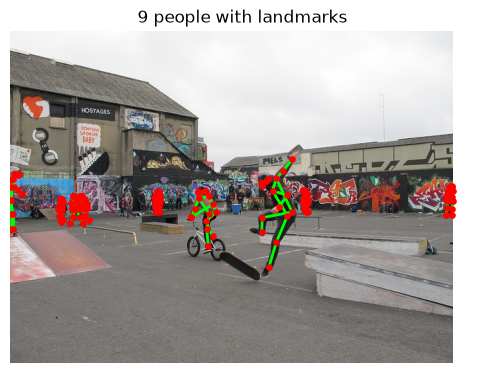

left wrist of the skater: [388.0014  253.98824]
left knee angle: 174 degrees


In [7]:
skatepark = np.array(Image.open(urllib.request.urlopen("http://images.cocodataset.org/val2017/000000087038.jpg")).convert("RGB"))
found = people(skatepark, 0.9)
draw(skatepark, found, str(len(found)) + " people with landmarks")
plt.show()
skater = max(found, key=lambda p: p[:, 1].max() - p[:, 1].min())   # the tallest skeleton
print("left wrist of the skater:", point(skater, "left_wrist"))
print("left knee angle:", round(angle(skater, "left_hip", "left_knee", "left_ankle")), "degrees")

## 3. Your photos

**Ideas** (or think of your own) - every idea is a **rule on the points**:

- *Hand-raise detector* for a big lecture hall: is a wrist above the shoulders?
- *Posture checker* at a desk: is the back straight (angle shoulder-hip-knee)?
- *Exercise coach:* is the squat deep enough (knee angle under 100 degrees)?
- *Sitting or standing* in the canteen or at a bus stop
- *Pointing:* which way does someone point (wrist relative to elbow)?

Take photos of **classmates who agreed**. Put the **answer in the file name**:
start every photo with `yes_` or `no_` (for example `yes_sam_window.jpg`).
Half yes, half no, and vary them: near and far, sitting and standing, left and
right, a few borderline cases.

**Rules for taking photos**

- **People only with permission.** Only photograph people who say yes - accept
  a no. Other people in the school must not be recognisable: aim away, or
  photograph them from behind.
- **Never put photos of people online.** Not in your portfolio (it is public)
  and not in a shared folder outside the group. Before you upload this notebook
  anywhere: *Edit -> Clear all outputs*. Delete the photos after this week.
- **Make it hard for the model.** Different places, light, distances and
  angles, and a few difficult photos (crowded, dark, half hidden). A test with
  only easy photos tells you nothing.
- **Enough photos:** at least 10, more is better. Any phone photo works.

**Getting your photos into Colab:** `upload_to("photos")` from the laptop
(send them from your phone by AirDrop, e-mail or Google Drive first), drag a
zip into the file panel on the left and run `!unzip -q yourfile.zip -d photos`,
or use the laptop camera with `take_photo("photos", "name.jpg")`.

photos : 12 photos


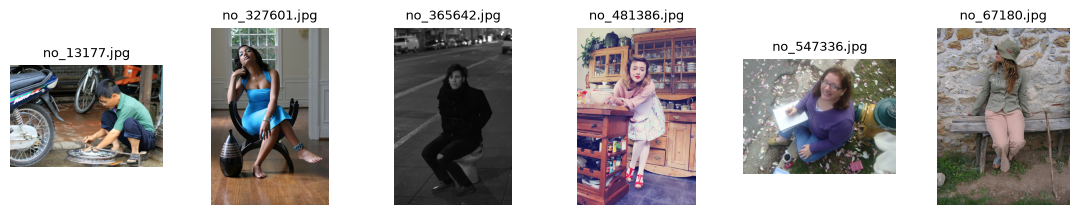

In [8]:
# upload_to("photos")                         # or a zip, or take_photo("photos", "yes_1.jpg")
folder = "photos"

# No photos yet? 12 example photos (half with a hand raised) let you test everything first.
# Delete these lines once your own photos are in the folder "photos".
os.makedirs("photos", exist_ok=True)
for label, ids in [("yes", [199055, 72281, 444142, 445792, 546717, 154425]),
                   ("no", [481386, 365642, 13177, 327601, 547336, 67180])]:
    for i in ids:
        target = os.path.join("photos", label + "_" + str(i) + ".jpg")
        if not os.path.exists(target):
            urllib.request.urlretrieve("http://images.cocodataset.org/val2017/" + str(i).zfill(12) + ".jpg", target)

photos = load_folder(folder)
show([photos[n] for n in photos][:6], list(photos)[:6], size=2.3)

## 4. Data processing

A phone photo is not ready for a model. Run the cell: it shows what happens to
one of your photos on its way in. **Use this for part 2 of your
presentation.**

1. the file from the phone:      640 x 427 pixels, RGB
2. turned the right way up:      no rotation needed (phones store the rotation separately, in the EXIF data)
3. made smaller (max 1024):      640 x 427 pixels
4. a grid of numbers:            (427, 640, 3) = 819840 numbers from 0 to 255
5. scaled to 0-1 for the model:  0.0 to 1.0


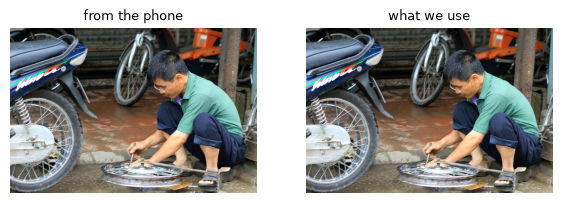

In [9]:
# Run, do not read: what happens to a phone photo before the model sees it
name = list(photos)[0]
original = Image.open(glob.glob(os.path.join(folder, name))[0])
print("1. the file from the phone:     ", original.size[0], "x", original.size[1], "pixels,", original.mode)
upright = ImageOps.exif_transpose(original)
print("2. turned the right way up:     ", "yes" if upright.size != original.size else "no rotation needed",
      "(phones store the rotation separately, in the EXIF data)")
print("3. made smaller (max 1024):     ", photos[name].shape[1], "x", photos[name].shape[0], "pixels")
print("4. a grid of numbers:           ", photos[name].shape, "=", photos[name].size, "numbers from 0 to 255")
x = TF.to_tensor(photos[name])
print("5. scaled to 0-1 for the model: ", round(float(x.min()), 2), "to", round(float(x.max()), 2))
show([np.array(original.convert("RGB")), photos[name]], ["from the phone", "what we use"])

**For landmark detection the data processing has one extra trap:** the
rotation (step 2). A photo that lies on its side gives a skeleton on its side,
and then "above" means something else. And remember: **y counts from the top**,
so a point that is higher in the photo has a **smaller** y.

**The ground truth** (section 6) is the answer in the file name (`yes_` /
`no_`), and for a few photos the true position of some points.

A photo needs to be prepared before the AI model can use it. First, the photo is rotated correctly and resized. Then the pixels are converted into numbers between 0 and 1.

This is important because the model needs numerical data to recognise body landmarks. If a photo is rotated incorrectly, the model might make mistakes when checking if a hand is raised.

## 5. Your MVP

Your app is a **rule** on the points. Change `my_rule` so it answers your
question with True or False, then run it on all your photos.

no_13177.jpg -> no


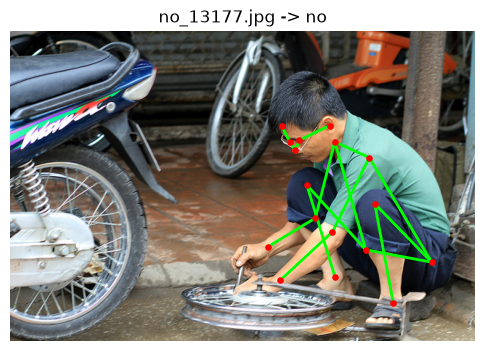

no_327601.jpg -> no


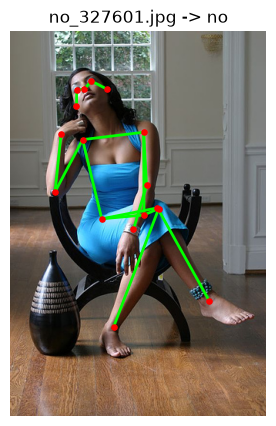

no_365642.jpg -> no


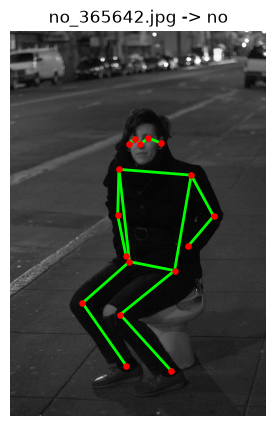

no_481386.jpg -> no


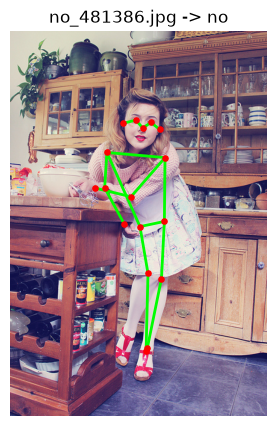

no_547336.jpg -> no


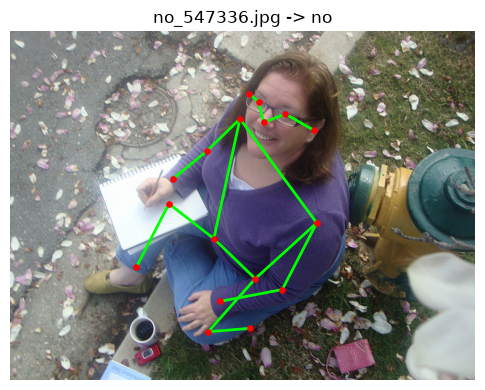

no_67180.jpg -> no


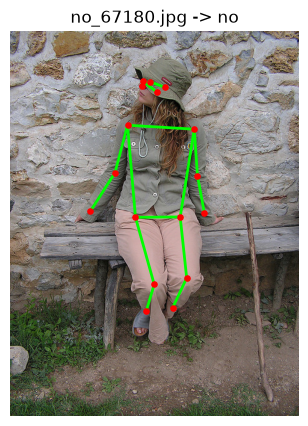

yes_154425.jpg -> YES


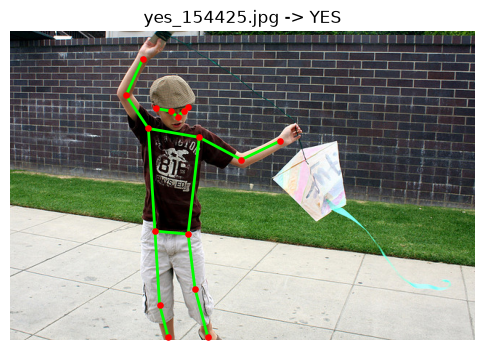

yes_199055.jpg -> YES


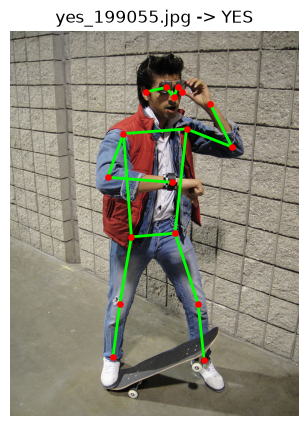

yes_444142.jpg -> YES


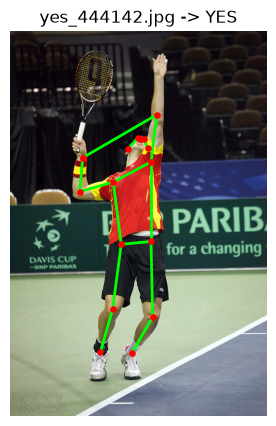

yes_445792.jpg -> YES


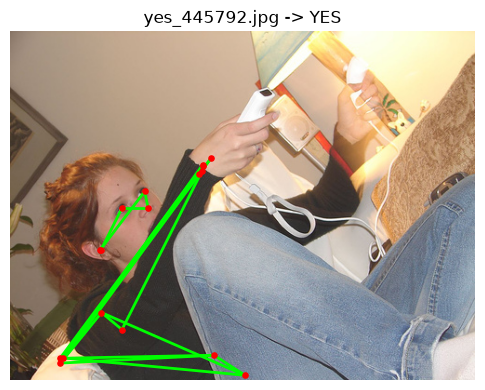

yes_546717.jpg -> YES


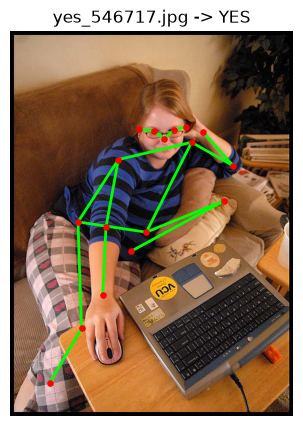

yes_72281.jpg -> YES


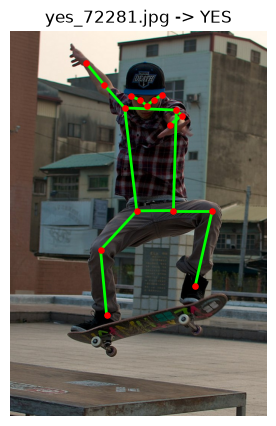

In [10]:
def my_rule(person):
    # Example: a hand is raised if a wrist is higher (smaller y!) than both shoulders
    highest_wrist = min(point(person, "left_wrist")[1], point(person, "right_wrist")[1])
    shoulders = min(point(person, "left_shoulder")[1], point(person, "right_shoulder")[1])
    return highest_wrist < shoulders

def my_app(picture, name=""):
    person = body(picture)
    if person is None:
        draw(picture, [], name)
        return "no person found"
    answer = my_rule(person)
    draw(picture, [person], name + " -> " + ("YES" if answer else "no"))
    return "YES" if answer else "no"

for name in photos:
    print(name, "->", my_app(photos[name], name))
    plt.show()

Our MVP is a hand-raise detector. It uses landmark detection to find the shoulders and wrists of a person.

The app checks if one wrist is higher than the shoulders. If this is true, the app predicts YES. Otherwise, it predicts NO.

This could be useful in classrooms to detect when students raise their hands.

## 6. Ground truth

Two kinds:

1. **The answer per photo** is already in the file name: `yes_...` or `no_...`.
2. **The position of the points.** Pick 2 or 3 photos and 3 landmarks (for example
   the nose, a wrist and a knee). Draw the photo with a grid using
   `draw(photos[name], [], grid=True)`, read off where each point **really**
   is, and type it in `true_points`.

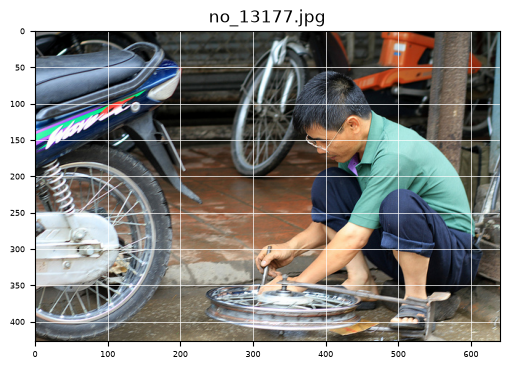

In [11]:
name = list(photos)[0]
draw(photos[name], [], name, grid=True)
plt.show()

In [12]:
true_points = {   # read off the grid by you (these are for two example photos, from the COCO annotations)
    "yes_199055.jpg": {"nose": [271, 112], "left_wrist": [328, 126], "left_knee": [309, 462]},
    "yes_444142.jpg": {"nose": [216, 178], "left_wrist": [246, 75], "left_knee": [234, 468]},
}

Ground truth is the correct answer that we use to evaluate the AI model.

For our hand-raise detector, the photos are labelled YES or NO depending on whether a person is raising their hand.

We can compare these labels with the model's predictions. We can also compare the predicted landmark positions with manually measured positions.

## 7. Evaluate

**The app (your rule):** the confusion matrix compares your rule with the file
names. **Accuracy** = right / all, **precision** = of the YES answers, how many
were right, **recall** = of the real yeses, how many did the app find.

**The landmarks (the model):** the **distance in pixels** between the model's
point and your point, and **PCK** = the share of points within a chosen
distance (here 10 % of the photo width).

In [13]:
# Run, do not read
def evaluate_rule(rule):
    tp = fp = fn = tn = 0
    wrong = []
    for name in photos:
        truth = name.lower().startswith("yes")
        person = body(photos[name])
        said = person is not None and bool(rule(person))
        tp += truth and said
        fp += (not truth) and said
        fn += truth and not said
        tn += (not truth) and not said
        if said != truth:
            wrong.append(name)
    print("                 really yes   really no")
    print("app says YES     ", str(tp).rjust(8), str(fp).rjust(11))
    print("app says no      ", str(fn).rjust(8), str(tn).rjust(11))
    print("accuracy ", round((tp + tn) / max(1, tp + fp + fn + tn), 2),
          " precision", round(tp / (tp + fp), 2) if tp + fp else "-",
          " recall", round(tp / (tp + fn), 2) if tp + fn else "-")
    return wrong

def evaluate_points():
    distances = []
    for name, points in true_points.items():
        person = body(photos[name])
        width = photos[name].shape[1]
        for p, xy in points.items():
            d = float(np.linalg.norm(point(person, p) - np.array(xy)))
            distances.append(d / width)
            print(name, p.ljust(12), "model", np.round(point(person, p)).astype(int), " you", xy, " off by", round(d), "pixels")
    distances = np.array(distances)
    print("PCK (within 10% of the photo width):", round(float((distances < 0.1).mean()), 2))

wrong = evaluate_rule(my_rule)
print()
evaluate_points()

                 really yes   really no
app says YES             6           0
app says no              0           6
accuracy  1.0  precision 1.0  recall 1.0

yes_199055.jpg nose         model [272 109]  you [271, 112]  off by 3 pixels
yes_199055.jpg left_wrist   model [332 121]  you [328, 126]  off by 6 pixels
yes_199055.jpg left_knee    model [312 453]  you [309, 462]  off by 10 pixels
yes_444142.jpg nose         model [215 179]  you [216, 178]  off by 1 pixels
yes_444142.jpg left_wrist   model [121 210]  you [246, 75]  off by 184 pixels
yes_444142.jpg left_knee    model [237 475]  you [234, 468]  off by 7 pixels
PCK (within 10% of the photo width): 0.83


Look at the photos the app got wrong. Was the **skeleton** wrong (the
model), or was the skeleton right and your **rule** too simple (your app)?
Improve the rule and run `evaluate_rule(my_rule)` again.

In [14]:
for name in wrong:
    my_app(photos[name], "wrong: " + name)
    plt.show()

### Your evaluation conclusions


Our hand-raise detector achieved an accuracy of 100%, a precision of 100% and a recall of 100% on the 12 example photos.

The model correctly identified all 6 photos with a raised hand and all 6 photos without a raised hand.

The PCK score was 0.83, which means that 83% of the tested landmarks were close enough to the manually labelled positions.

However, the model made a large mistake when predicting the left wrist in one photo. The difference was 184 pixels.

I think the app works well on these example photos, but it should be tested on more photos with different lighting, angles and people before being used in a real classroom.

## 8. End result and presentation checklist

Make the pictures for your slides with `save_result("name.png")` (in the same
cell as the picture) and download them all with `download_results()`.

| Part of your presentation | Where in this notebook | Done? |
|---------------------------|------------------------|-------|
| 1. What is the technique? input, output, what is it for | section 1 | |
| 2. Which data processing is needed? photo -> model, and the ground truth | sections 4 and 6 | |
| 3. What did you do? your idea, your photos, how you built your MVP | sections 3 and 5 | |
| 4. How do you evaluate it? metric, why, your result | section 7 | |
| 5. The end result: your MVP working, and where it fails | section 8 | |
| Extra: model or rule - who made the mistakes? | section 7 | |

Also prepare an answer to: **who could this app fail, and who could be harmed
by it?** The class will ask.

saved results/example_yes.png


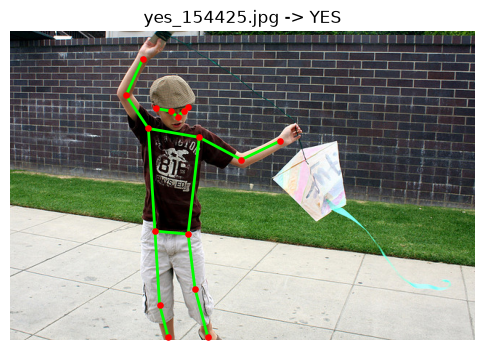

saved results/example_no.png


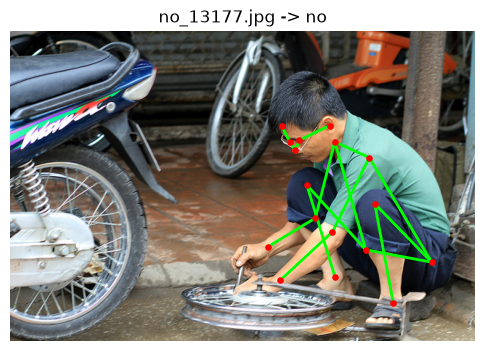

In [15]:
# The end result: your app on a YES and a no photo - saved for the slides
yes_photo = [n for n in photos if n.startswith("yes")][0]
no_photo = [n for n in photos if n.startswith("no")][0]
for name, label in [(yes_photo, "yes"), (no_photo, "no")]:
    my_app(photos[name], name)
    save_result("example_" + label + ".png")
    plt.show()
# download_results()